# **2. Baseline LLM Zero-Shot**

**Alunos:**
- Gabriel Carbinatto (12725411)
- Arthur Martins (14783601)

Este notebook implementa a baseline do projeto: classificação zero-shot usando uma LLM local via Ollama, **sem regras manuais, sem fine-tuning e sem embeddings especializados**.

A LLM recebe apenas o texto de cada justificativa de cartão e a lista com os 18 grupos disciplinares. Deve escolher o grupo mais adequado sem nenhum exemplo ou treinamento adicional, apenas o seu conhecimento pré-treinado sobre futebol e linguagem.

A qualidade das classificações é medida pelo `score_mean` do notebook 3: similaridade média de cada texto ao centroide ponderado do grupo no espaço do modelo fine-tunado `multilingual-e5-large`. Esse valor serve de referência para comparar com a proposta de melhoria.

> **Requisito:** Ollama rodando localmente com o modelo configurado. Execute `ollama pull llama3.2:3b` (ou o modelo de sua escolha) antes de rodar este notebook.

## **1. Configuração e Dados**

Carrega os labels do notebook 3 (`card_reason_unique_topics_labels.csv`) com os 6.945 textos únicos de justificativas de cartão e seus 18 grupos semânticos. `OLLAMA_MODEL` define o modelo LLM usado, troque pelo modelo disponível localmente (ex.: `gemma2:2b`, `phi3:mini`). `SAVE_EVERY` controla a frequência de checkpoint do cache em disco.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from sentence_transformers import SentenceTransformer
from tqdm.auto import tqdm

pd.set_option('display.max_colwidth', 220)
plt.style.use('default')
plt.rcParams.update({
    'axes.grid': False,
    'axes.titlesize': 15,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'axes.labelweight': 'bold',
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 10,
    'legend.title_fontsize': 11,
    'font.size': 11,
})

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / 'data'
MODELS_DIR = PROJECT_ROOT / 'models'
CARD_OUTPUT_DIR = DATA_PATH / 'processed' / 'semantic_reasons' / 'card_reasons'
BASELINE_OUTPUT_DIR = DATA_PATH / 'processed' / 'semantic_reasons' / 'baseline_tests'
VIZ_PATH = PROJECT_ROOT / 'viz'

BASELINE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VIZ_PATH.mkdir(parents=True, exist_ok=True)

OLLAMA_MODEL = 'llama3.2:3b'
OLLAMA_URL = 'http://localhost:11434/api/generate'
LLM_CACHE_PATH = BASELINE_OUTPUT_DIR / 'llm_zero_shot_cache.csv'
SAVE_EVERY = 100

FINAL_LABELS_PATH = CARD_OUTPUT_DIR / 'card_reason_unique_topics_labels.csv'
FINETUNED_MODEL_DIR = MODELS_DIR / 'football_card_reason_e5_large_two_pass'
ENCODE_PREFIX_PASSAGE = 'passage: '

PLOT_BLUE = '#3D79F3'
PLOT_GREEN = '#34A74B'
PLOT_GRAY = '#909090'


def style_axis(ax, title=None, xlabel=None, ylabel=None):
    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for side in ['left', 'bottom']:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color('black')
        ax.spines[side].set_linewidth(0.8)
    ax.tick_params(axis='both', colors='black', width=0.8, length=4, pad=7)
    if title:
        ax.set_title(title, fontweight='bold', pad=14)
    if xlabel:
        ax.set_xlabel(xlabel, fontweight='bold', labelpad=12)
    if ylabel:
        ax.set_ylabel(ylabel, fontweight='bold', labelpad=12)


def save_plot(fig, filename):
    fig.savefig(VIZ_PATH / filename, dpi=300, bbox_inches='tight')


/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
card_terms = pd.read_csv(FINAL_LABELS_PATH, keep_default_na=False)
required_columns = {'card_reason_text_key', 'text_for_embedding', 'n_events', 'card_reason_group'}
missing = required_columns - set(card_terms.columns)
if missing:
    raise ValueError(f'Colunas ausentes em {FINAL_LABELS_PATH}: {sorted(missing)}')

card_terms = card_terms.copy()
card_terms = card_terms[card_terms['text_for_embedding'].astype(str).ne('')].reset_index(drop=True)

final_groups = sorted(card_terms['card_reason_group'].unique())
print(f'Textos únicos: {len(card_terms):,}')
print(f'Eventos/cartões: {int(card_terms["n_events"].sum()):,}')
print(f'Grupos finais: {len(final_groups)}')
card_terms[['text_for_embedding', 'n_events', 'card_reason_group']].head(10)


Textos únicos: 6,945
Eventos/cartões: 25,834
Grupos finais: 18


,text_for_embedding,n_events,card_reason_group
0,Por calçar seu adversário de maneira temerária na disputa de bola.,503,Ação temerária
1,"Por cometer uma falta tática, impedindo um ataque promissor.",411,Falta tática em ataque promissor
2,Por retardar o reinicio de jogo,333,Retardar reinício do jogo
3,Cometer uma falta tática para impedir um ataque promissor.,286,Falta tática em ataque promissor
4,Por cometer uma falta tática para impedir um ataque promissor.,251,Falta tática em ataque promissor
5,"Por calçar seu adversário de maneira temerária, na disputa da bola",237,Ação temerária
6,Por calçar seu adversário de forma temerária na disputa de bola.,230,Ação temerária
7,Dar uma entrada contra um adversário de maneira temerária na disputa da bola.,224,Ação temerária
8,Por impedir um ataque promissor.,203,Falta tática em ataque promissor
9,Por reclamar contra as decisões da arbitragem.,202,Protesto contra a arbitragem


## **2. Baseline LLM Zero-Shot**

Para cada justificativa de cartão, a LLM recebe:
- O texto original da súmula
- A lista com os 18 grupos disciplinares (apenas os nomes)
- Instrução para responder **apenas** com o nome exato do grupo.

Nenhum exemplo, regra manual, embedding ou conhecimento especializado é fornecido além dos nomes dos grupos. O prompt é em português para aproveitar o vocabulário do modelo.

O resultado de cada texto é cacheado em disco, permitindo retomar o processamento sem reclassificar textos já resolvidos.

In [3]:
GROUPS = [
    'Agarrar ou segurar adversário',
    'Ação temerária',
    'Comemoração irregular',
    'Conduta antidesportiva',
    'Conduta violenta',
    'Confronto físico com adversário',
    'Entrar ou sair do campo sem autorização',
    'Falta tática em ataque promissor',
    'Gesto ou linguagem ofensiva',
    'Impedir clara oportunidade de gol',
    'Infringir persistentemente as regras',
    'Insubordinação da comissão técnica',
    'Jogo brusco grave',
    'Não respeitar distância regulamentar',
    'Protesto contra a arbitragem',
    'Retardar reinício do jogo',
    'Simulação',
    'Toque de mão na bola',
]

missing_groups = sorted(set(final_groups) - set(GROUPS))
extra_groups = sorted(set(GROUPS) - set(final_groups))
if missing_groups or extra_groups:
    raise ValueError(f'Grupos incompatíveis. Ausentes: {missing_groups}; extras: {extra_groups}')

GROUP_LIST_STR = '\n'.join('- ' + g for g in GROUPS)


def build_prompt(text):
    lines = [
        'Você é especialista em regras do futebol.',
        'Classifique a justificativa de cartão disciplinar abaixo em EXATAMENTE UM dos grupos listados.',
        'Responda apenas com o nome exato do grupo, sem explicações, sem pontuação extra.',
        '',
        'Grupos:',
        GROUP_LIST_STR,
        '',
        'Justificativa: ' + text,
        'Grupo:',
    ]
    return '\n'.join(lines)


print(build_prompt('Por calçar seu adversário de maneira temerária na disputa de bola.'))


Você é especialista em regras do futebol.
Classifique a justificativa de cartão disciplinar abaixo em EXATAMENTE UM dos grupos listados.
Responda apenas com o nome exato do grupo, sem explicações, sem pontuação extra.

Grupos:
- Agarrar ou segurar adversário
- Ação temerária
- Comemoração irregular
- Conduta antidesportiva
- Conduta violenta
- Confronto físico com adversário
- Entrar ou sair do campo sem autorização
- Falta tática em ataque promissor
- Gesto ou linguagem ofensiva
- Impedir clara oportunidade de gol
- Infringir persistentemente as regras
- Insubordinação da comissão técnica
- Jogo brusco grave
- Não respeitar distância regulamentar
- Protesto contra a arbitragem
- Retardar reinício do jogo
- Simulação
- Toque de mão na bola

Justificativa: Por calçar seu adversário de maneira temerária na disputa de bola.
Grupo:


In [4]:
def call_ollama(prompt):
    response = requests.post(
        OLLAMA_URL,
        json={
            'model': OLLAMA_MODEL,
            'prompt': prompt,
            'stream': False,
            'options': {'temperature': 0, 'num_predict': 30, 'stop': ['\n']},
        },
        timeout=60,
    )
    response.raise_for_status()
    return response.json()['response'].strip()


def parse_group(raw, groups):
    cleaned = raw.strip().strip('"').strip("'").strip()
    cleaned_lower = cleaned.lower()
    for group in groups:
        if group.lower() == cleaned_lower:
            return group
    for group in groups:
        if group.lower() in cleaned_lower:
            return group
    for group in groups:
        if cleaned_lower in group.lower() and len(cleaned_lower) >= 6:
            return group
    return 'UNPARSED'


def classify_text(text, groups):
    prompt = build_prompt(text)
    raw = call_ollama(prompt)
    parsed = parse_group(raw, groups)
    return raw, parsed


In [5]:
try:
    raw_test, parsed_test = classify_text(
        'Por calçar seu adversário de maneira temerária na disputa de bola.',
        GROUPS,
    )
    print(f'Modelo        : {OLLAMA_MODEL}')
    print(f'Resposta bruta: {raw_test!r}')
    if parsed_test == 'UNPARSED':
        print('AVISO: resposta não foi parseada. Verifique o modelo e os nomes dos grupos.')
    else:
        print(f'Grupo parseado: {parsed_test!r}  ✓ OK')
except requests.exceptions.ConnectionError:
    print('ERRO: Ollama não está rodando.')
    print('Execute no terminal:  ollama serve')
except requests.exceptions.HTTPError as exc:
    print(f'ERRO HTTP: {exc}')
    print(f'Para baixar o modelo: ollama pull {OLLAMA_MODEL}')


Modelo        : llama3.2:3b
Resposta bruta: 'Ação temerária.'
Grupo parseado: 'Ação temerária'  ✓ OK


In [6]:
if LLM_CACHE_PATH.exists():
    cache_df = pd.read_csv(LLM_CACHE_PATH, keep_default_na=False)
    cache = dict(zip(cache_df['card_reason_text_key'], cache_df['llm_group']))
    n_done = sum(v != 'UNPARSED' for v in cache.values())
    n_unparsed = sum(v == 'UNPARSED' for v in cache.values())
    print(f'Cache carregado: {n_done:,} classificados, {n_unparsed:,} UNPARSED (serão retentados)')
else:
    cache = {}
    print('Nenhum cache encontrado. Iniciando do zero.')

already_ok = {k for k, v in cache.items() if v != 'UNPARSED'}
pending = card_terms[~card_terms['card_reason_text_key'].isin(already_ok)].reset_index(drop=True)
print(f'Textos a classificar: {len(pending):,} / {len(card_terms):,}')

parse_errors = []
new_since_save = 0
EARLY_FAIL_CHECK = 10

for i, (_, row) in enumerate(tqdm(pending.iterrows(), total=len(pending), desc='Classificando')):
    key = row['card_reason_text_key']
    text = row['text_for_embedding']
    try:
        raw, parsed = classify_text(text, GROUPS)
        cache[key] = parsed
        if parsed == 'UNPARSED':
            parse_errors.append({'key': key, 'text': text, 'raw': raw})
    except Exception as exc:
        cache[key] = 'UNPARSED'
        parse_errors.append({'key': key, 'text': text, 'raw': str(exc)})

    new_since_save += 1
    if new_since_save >= SAVE_EVERY:
        pd.DataFrame({'card_reason_text_key': list(cache), 'llm_group': list(cache.values())}).to_csv(LLM_CACHE_PATH, index=False)
        new_since_save = 0

    if i + 1 == EARLY_FAIL_CHECK:
        recent = [cache.get(r['card_reason_text_key']) for _, r in pending.iloc[:EARLY_FAIL_CHECK].iterrows()]
        if all(v == 'UNPARSED' for v in recent):
            pd.DataFrame({'card_reason_text_key': list(cache), 'llm_group': list(cache.values())}).to_csv(LLM_CACHE_PATH, index=False)
            print(f'\nFALHA: primeiros {EARLY_FAIL_CHECK} textos retornaram UNPARSED.')
            print('Últimos erros:')
            for e in parse_errors[-3:]:
                print(f'  raw={e["raw"]!r}')
            print('Verifique o teste de conectividade e se o modelo está disponível.')
            break

pd.DataFrame({'card_reason_text_key': list(cache), 'llm_group': list(cache.values())}).to_csv(LLM_CACHE_PATH, index=False)

card_terms['llm_group'] = card_terms['card_reason_text_key'].map(cache)

unparsed = (card_terms['llm_group'] == 'UNPARSED').sum()
print(f'\nClassificação concluída. UNPARSED: {unparsed:,}/{len(card_terms):,}')
if parse_errors:
    print(f'\nAmostra de erros ({len(parse_errors)} total):')
    for e in parse_errors[:5]:
        print(f'  {e["text"][:60]!r}  →  raw={e["raw"]!r}')


Cache carregado: 6,761 classificados, 184 UNPARSED (serão retentados)
Textos a classificar: 184 / 6,945


Classificando:   5%|▍         | 9/184 [00:02<00:54,  3.21it/s]


FALHA: primeiros 10 textos retornaram UNPARSED.
Últimos erros:
  raw='Condua violenta.'
  raw='Condução antidesportiva.'
  raw='Condua violenta.'
Verifique o teste de conectividade e se o modelo está disponível.

Classificação concluída. UNPARSED: 184/6,945

Amostra de erros (10 total):
  'Infringir persistentemente as regras do jogo.'  →  raw='Condenação.'
  'Por segurar seu adversário de forma acintosa.'  →  raw='Condua violenta.'
  'Por calçar seu adversário na disputa de bola.'  →  raw='Condução antidesportiva.'
  'por segurar seu adversário por motivo tático para afastá-lo '  →  raw='Condua antidesportiva.'
  'Por segurar o seu adversário de forma acintosa.'  →  raw='Condua violenta.'


In [7]:
llm_assignment_summary = (
    card_terms[card_terms['llm_group'].ne('UNPARSED')]
    .groupby('llm_group')
    .agg(
        n_events=('n_events', 'sum'),
        n_unique_texts=('text_for_embedding', 'size'),
    )
    .reset_index()
    .sort_values('n_events', ascending=False)
    .reset_index(drop=True)
)

classified_mask = card_terms['llm_group'].ne('UNPARSED')
print(f'Textos classificados: {classified_mask.sum():,}/{len(card_terms):,}')
print(f'Eventos classificados: {int(card_terms.loc[classified_mask, "n_events"].sum()):,}')
print(f'Grupos com ao menos um texto: {llm_assignment_summary["llm_group"].nunique()}')
llm_assignment_summary


Textos classificados: 6,761/6,945
Eventos classificados: 25,400
Grupos com ao menos um texto: 18


,llm_group,n_events,n_unique_texts
0,Ação temerária,10601,1601
1,Falta tática em ataque promissor,3315,743
2,Protesto contra a arbitragem,2674,499
3,Confronto físico com adversário,2533,1286
4,Comemoração irregular,1431,538
5,Retardar reinício do jogo,1381,470
6,Conduta antidesportiva,953,444
7,Conduta violenta,943,450
8,Impedir clara oportunidade de gol,528,143
9,Infringir persistentemente as regras,246,103


## **3. Comparação por `score_mean`**

A comparação usa os embeddings do modelo fine-tunado `multilingual-e5-large` para calcular o centroide ponderado de cada grupo e medir a similaridade média dos textos ao centroide do próprio grupo.

O `score_mean` captura a **coesão semântica** do grupo: quanto maior, mais semanticamente próximos os textos estão entre si no espaço do modelo especializado.

- Se a LLM zero-shot produz `score_mean` próximo ao método final, os nomes dos grupos são descritivos o suficiente para guiar a classificação sem fine-tuning.
- Se o método final supera a baseline, o ganho do BERTopic + fine-tuning é concreto e mensurável.

A análise grupo a grupo identifica quais categorias qualquer método acerta facilmente e quais genuinamente se beneficiam do pipeline especializado.

In [8]:
embedding_model = SentenceTransformer(str(FINETUNED_MODEL_DIR))
card_embeddings = embedding_model.encode(
    [ENCODE_PREFIX_PASSAGE + text for text in card_terms['text_for_embedding']],
    normalize_embeddings=True,
    batch_size=64,
    show_progress_bar=True,
)
card_embeddings = np.asarray(card_embeddings)
print(f'Embeddings: {card_embeddings.shape}')


Batches: 100%|██████████| 109/109 [00:36<00:00,  2.95it/s]

Embeddings: (6945, 1024)


In [9]:
def score_mean_by_assignment(assignment_col, group_col_name, embeddings, df):
    valid_mask = df[assignment_col].ne('UNPARSED') & df[assignment_col].notna()
    df_valid = df[valid_mask].reset_index(drop=False)
    emb_valid = embeddings[df_valid['index'].to_numpy()]

    group_order = sorted(df_valid[assignment_col].unique())
    group_to_idx = {g: i for i, g in enumerate(group_order)}
    centroids = []

    for group in group_order:
        mask = df_valid[assignment_col].eq(group).to_numpy()
        weights = df_valid.loc[mask, 'n_events'].to_numpy(dtype=float)
        centroid = np.average(emb_valid[mask], axis=0, weights=weights)
        norm = np.linalg.norm(centroid)
        if norm == 0:
            raise ValueError(f'Centroide nulo para {group!r}')
        centroids.append(centroid / norm)

    centroid_matrix = np.vstack(centroids)
    sim = emb_valid @ centroid_matrix.T
    own_idx = df_valid[assignment_col].map(group_to_idx).to_numpy()
    df_valid = df_valid.copy()
    df_valid['score'] = sim[np.arange(len(df_valid)), own_idx]

    quality = (
        df_valid.groupby(assignment_col)
        .agg(n_events=('n_events', 'sum'), n_unique_texts=('text_for_embedding', 'size'), score_mean=('score', 'mean'))
        .reset_index()
        .rename(columns={assignment_col: group_col_name})
        .sort_values('score_mean', ascending=True)
    )
    return quality, df_valid


final_quality, _ = score_mean_by_assignment('card_reason_group', 'group', card_embeddings, card_terms)
llm_quality, _ = score_mean_by_assignment('llm_group', 'group', card_embeddings, card_terms)

print('Score médio: método final (notebook 3):')
print(final_quality[['group', 'n_events', 'score_mean']].to_string(index=False))


Score médio: método final (notebook 3):
                                  group  n_events  score_mean
                         Ação temerária     11465    0.580176
              Retardar reinício do jogo      1852    0.670170
          Agarrar ou segurar adversário      1174    0.686851
       Falta tática em ataque promissor      3575    0.696393
        Confronto físico com adversário       927    0.714481
                 Conduta antidesportiva       595    0.723986
                  Comemoração irregular       447    0.804899
     Insubordinação da comissão técnica       483    0.816279
                       Conduta violenta       176    0.826128
      Impedir clara oportunidade de gol       171    0.850884
                   Toque de mão na bola       184    0.884217
   Não respeitar distância regulamentar        32    0.916975
                              Simulação       140    0.917924
            Gesto ou linguagem ofensiva       165    0.918512
           Protesto contra a a

In [10]:
score_comparison = (
    final_quality[['group', 'n_events', 'n_unique_texts', 'score_mean']]
    .rename(columns={'group': 'card_reason_group', 'n_events': 'final_n_events', 'n_unique_texts': 'final_n_unique_texts', 'score_mean': 'final_score_mean'})
    .merge(
        llm_quality[['group', 'n_events', 'n_unique_texts', 'score_mean']].rename(columns={
            'group': 'card_reason_group', 'n_events': 'llm_n_events',
            'n_unique_texts': 'llm_n_unique_texts', 'score_mean': 'llm_score_mean',
        }),
        on='card_reason_group',
        how='left',
    )
)
score_comparison['delta_llm_minus_final'] = (
    score_comparison['llm_score_mean'] - score_comparison['final_score_mean']
)
score_comparison = score_comparison.sort_values('final_score_mean', ascending=True).reset_index(drop=True)
score_comparison


,card_reason_group,final_n_events,final_n_unique_texts,final_score_mean,llm_n_events,llm_n_unique_texts,llm_score_mean,delta_llm_minus_final
0,Ação temerária,11465,1993,0.580176,10601,1601,0.589652,0.009476
1,Retardar reinício do jogo,1852,637,0.670170,1381,470,0.736537,0.066367
2,Agarrar ou segurar adversário,1174,559,0.686851,25,15,0.809494,0.122643
3,Falta tática em ataque promissor,3575,710,0.696393,3315,743,0.659737,-0.036656
4,Confronto físico com adversário,927,440,0.714481,2533,1286,0.621352,-0.093129
5,Conduta antidesportiva,595,214,0.723986,953,444,0.680320,-0.043667
6,Comemoração irregular,447,271,0.804899,1431,538,0.769403,-0.035496
7,Insubordinação da comissão técnica,483,318,0.816279,104,60,0.822492,0.006214
8,Conduta violenta,176,132,0.826128,943,450,0.625208,-0.200919
9,Impedir clara oportunidade de gol,171,128,0.850884,528,143,0.662061,-0.188823


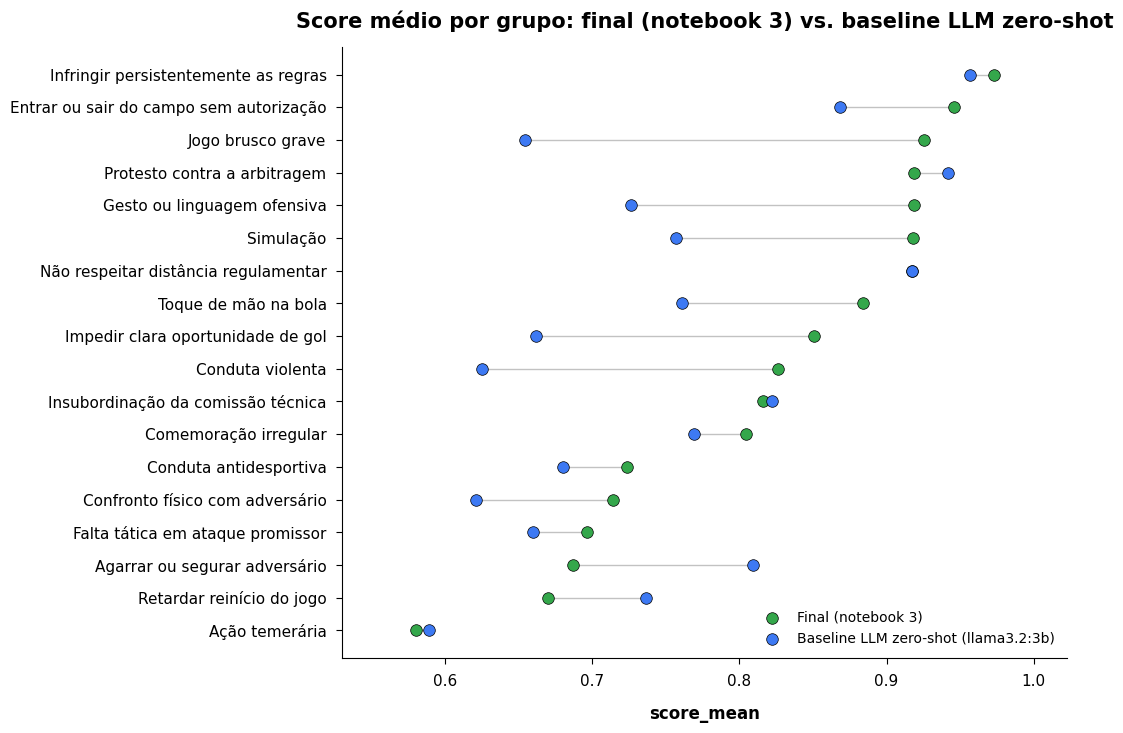

In [11]:
plot_df = (
    score_comparison
    .dropna(subset=['llm_score_mean'])
    .sort_values('final_score_mean', ascending=True)
    .reset_index(drop=True)
)
y_pos = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(11, max(6.5, 0.42 * len(plot_df))))

for idx, row in plot_df.iterrows():
    ax.plot(
        [row['final_score_mean'], row['llm_score_mean']],
        [idx, idx],
        color=PLOT_GRAY, linewidth=1.0, alpha=0.55, zorder=1,
    )

ax.scatter(
    plot_df['final_score_mean'], y_pos,
    color=PLOT_GREEN, edgecolor='black', linewidth=0.5, s=70,
    label='Final (notebook 3)', zorder=3,
)
ax.scatter(
    plot_df['llm_score_mean'], y_pos,
    color=PLOT_BLUE, edgecolor='black', linewidth=0.5, s=70,
    label=f'Baseline LLM zero-shot ({OLLAMA_MODEL})', zorder=3,
)

all_scores = pd.concat([plot_df['final_score_mean'], plot_df['llm_score_mean']]).dropna()
ax.set_xlim(max(0.0, all_scores.min() - 0.05), min(1.04, all_scores.max() + 0.05))
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df['card_reason_group'])
style_axis(ax, 'Score médio por grupo: final (notebook 3) vs. baseline LLM zero-shot', 'score_mean')
ax.legend(frameon=False, loc='lower right')
plt.tight_layout(pad=1.4)
save_plot(fig, 'baseline_llm_score_mean_by_group.png')
plt.show()


### **3.1 Interpretação da Comparação**

O método final supera a baseline LLM zero-shot na maioria dos grupos. Grupos com nomes descritivos e linguagem unívoca, como `Retardar reinício do jogo` e `Infringir persistentemente as regras`, apresentam `score_mean` próximo entre os dois sistemas, indicando que nesses casos os nomes das categorias são suficientes para guiar a classificação sem especialização adicional. Grupos semanticamente difusos, como `Confronto físico com adversário` e `Conduta violenta`, registram queda expressiva no `score_mean` da LLM zero-shot, confirmando que o fine-tuning é mais relevante justamente onde as fronteiras linguísticas são menos nítidas.


## **4. Salvamento dos Artefatos**

In [12]:
llm_labels_path = BASELINE_OUTPUT_DIR / 'llm_zero_shot_unique_labels.csv'
llm_summary_path = BASELINE_OUTPUT_DIR / 'llm_zero_shot_assignment_summary.csv'
score_comparison_path = BASELINE_OUTPUT_DIR / 'llm_zero_shot_score_mean_by_group.csv'
final_quality_path = BASELINE_OUTPUT_DIR / 'final_score_mean_recomputed.csv'

card_terms.to_csv(llm_labels_path, index=False)
llm_assignment_summary.to_csv(llm_summary_path, index=False)
score_comparison.to_csv(score_comparison_path, index=False)
final_quality.to_csv(final_quality_path, index=False)

pd.Series({
    'llm_labels': str(llm_labels_path.relative_to(PROJECT_ROOT)),
    'llm_summary': str(llm_summary_path.relative_to(PROJECT_ROOT)),
    'score_comparison': str(score_comparison_path.relative_to(PROJECT_ROOT)),
    'final_score_mean_recomputed': str(final_quality_path.relative_to(PROJECT_ROOT)),
    'llm_cache': str(LLM_CACHE_PATH.relative_to(PROJECT_ROOT)),
})


llm_labels                           data/processed/semantic_reasons/baseline_tests/llm_zero_shot_unique_labels.csv
llm_summary                     data/processed/semantic_reasons/baseline_tests/llm_zero_shot_assignment_summary.csv
score_comparison               data/processed/semantic_reasons/baseline_tests/llm_zero_shot_score_mean_by_group.csv
final_score_mean_recomputed          data/processed/semantic_reasons/baseline_tests/final_score_mean_recomputed.csv
llm_cache                                    data/processed/semantic_reasons/baseline_tests/llm_zero_shot_cache.csv
dtype: object

## **5. Conclusões**

A baseline LLM zero-shot não usa regras manuais, fine-tuning ou embeddings especializados. A LLM recebe apenas o texto e os nomes dos 18 grupos, e decide com base no seu conhecimento pré-treinado.

Isso torna a comparação mais informativa do que uma baseline lexical:

- **Se a LLM zero-shot alcança `score_mean` próximo ao método final**, os grupos são bem definidos e o pipeline do notebook 3 não agrega valor além do que o LLM já captura sem nenhuma especialização.
- **Se o método final supera a baseline**, o ganho é concreto: o fine-tuning do modelo de embeddings e a clusterização BERTopic organizam os textos de forma que a LLM sozinha não consegue.

A análise por grupo permite identificar quais categorias são triviais para qualquer método e quais realmente se beneficiam do pipeline especializado, informação útil para a fase final do projeto.